# 3 — Mise en service : scorer une alerte avec son historique

Le service reçoit les alertes dans l’ordre, conserve un historique récent, choisit quelques candidates puis estime un score de corrélation pour chaque paire. Il renvoie les identifiants des alertes rapprochées et les probabilités estimées.

**Analogie :** comme un enquêteur qui garde les derniers indices sur son tableau, le service compare un nouvel événement aux indices récents. Il propose des rapprochements ; il ne déclare pas seul qu’un incident est confirmé.

## Chaîne de traitement en production

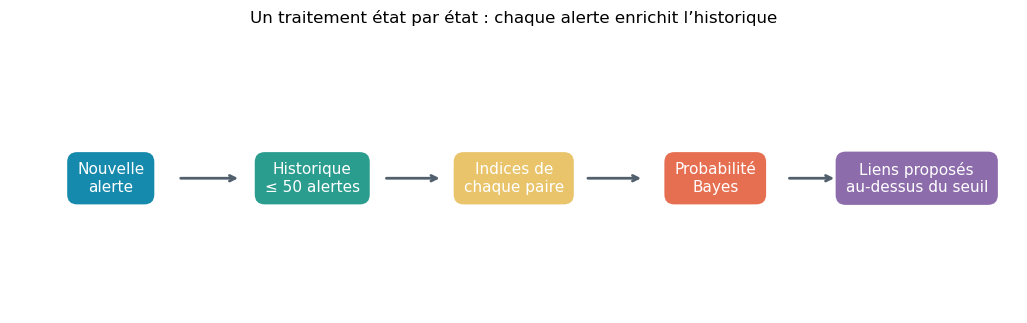

In [3]:
import matplotlib.pyplot as plt

# Slightly widened figure to give more breathing room
fig, ax = plt.subplots(figsize=(13, 3.5)) 
ax.set_xlim(0, 12); ax.set_ylim(0, 2.5); ax.axis('off') # Expanded xlim to 12

# Added line breaks (\n) and spaced out the coordinates evenly
steps = [
    (1.2, 'Nouvelle\nalerte'),
    (3.6, 'Historique\n≤ 50 alertes'),
    (6.0, 'Indices de\nchaque paire'),
    (8.4, 'Probabilité\nBayes'),
    (10.8, 'Liens proposés\nau-dessus du seuil')
]
colors = ['#168aad', '#2a9d8f', '#e9c46a', '#e76f51', '#8d6cab']

for (x, label), color in zip(steps, colors):
    ax.text(x, 1.25, label, ha='center', va='center', color='white', fontsize=11,
            bbox=dict(boxstyle='round,pad=.65', facecolor=color, edgecolor='none'))

# Adjusted arrow coordinates to fit the new evenly spaced boxes
for x1, x2 in [(2.0, 2.75), (4.45, 5.15), (6.85, 7.55), (9.25, 9.85)]:
    ax.annotate('', xy=(x2, 1.25), xytext=(x1, 1.25), 
                arrowprops=dict(arrowstyle='->', lw=2, color='#52606d'))

ax.set_title('Un traitement état par état : chaque alerte enrichit l’historique', pad=15)
plt.show()

In [4]:
from pathlib import Path
from html import escape
from collections import Counter
from datetime import datetime, timezone
import sys, json
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT=Path.cwd()
if not (ROOT/'src'/'alert_correlation').exists():
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from alert_correlation.core import load_alerts, stream_correlator, TEST_SCENARIOS

model=json.loads((ROOT/'artifacts'/'alert_correlation'/'bayesian_alert_correlation_model.json').read_text(encoding='utf-8'))
threshold=model['decision_threshold']
score_alert=stream_correlator(model,threshold=threshold)
print('Seuil du modèle :',threshold)
print('Historique maximal :',model['max_history'],'alertes')
print('Écart maximal :',model['max_gap_seconds']//60,'minutes')
print('Indices :',', '.join(model['features']))

def show_table(headers,body):
    head=''.join(f'<th>{escape(str(h))}</th>' for h in headers)
    rows=''.join('<tr>'+''.join(f'<td>{escape(str(v))}</td>' for v in row)+'</tr>' for row in body)
    display(HTML(f'<table><thead><tr>{head}</tr></thead><tbody>{rows}</tbody></table>'))

Seuil du modèle : 0.04
Historique maximal : 50 alertes
Écart maximal : 30 minutes
Indices : same_host, same_detector, same_signature, gap_le_10s, gap_le_60s


## Que signifie chaque champ de la réponse ?

`correlation_probability` est le plus grand score parmi les candidates retenues pour l’alerte courante. `related_to` détaille les candidates qui dépassent le seuil. `correlated` est simplement vrai si cette liste n’est pas vide.

Le seuil provient du notebook de modélisation. Dans cette démonstration, il a été choisi sur des scénarios d’entraînement à partir des labels faibles AIT-ADS ; il ne doit pas être interprété comme un seuil calibré pour un SOC réel.

In [5]:
show_table(
    ['Champ de sortie','Signification'],
    [
        ['alert_id','Identifiant de l’alerte reçue'],
        ['correlation_probability','Score le plus élevé parmi les paires candidates retenues'],
        ['related_to','Identifiants des alertes précédentes proposées comme liées et leurs scores'],
        ['correlated','Vrai si au moins une candidate dépasse le seuil'],
        ['threshold','Seuil chargé depuis le modèle entraîné'],
    ]
)

Champ de sortie,Signification
alert_id,Identifiant de l’alerte reçue
correlation_probability,Score le plus élevé parmi les paires candidates retenues
related_to,Identifiants des alertes précédentes proposées comme liées et leurs scores
correlated,Vrai si au moins une candidate dépasse le seuil
threshold,Seuil chargé depuis le modèle entraîné


## Démonstration sur un extrait réel

Pour que l’exemple soit lisible, le code sélectionne d’abord quelques alertes du scénario test qui tombent dans une phase annotée. Cette sélection sert uniquement à choisir un extrait de démonstration. Les colonnes de label sont ensuite retirées **avant** l’appel au service : le scoreur ne reçoit ni `attack_phase` ni `is_attack`.

In [6]:
alerts=load_alerts(ROOT/'artifacts'/'alert_correlation'/'normalized_alerts.csv')
demo=[a.copy() for a in alerts if a['scenario'] in TEST_SCENARIOS and a['is_attack']==1]
demo.sort(key=lambda a:(a['timestamp_epoch'],a['event_id']))
demo=demo[:300]
for event in demo:
    event.pop('is_attack',None)
    event.pop('attack_phase',None)
responses=[score_alert(event) for event in demo]
linked=[r for r in responses if r['correlated']]
print(f'{len(responses)} alertes traitées ; {len(linked)} ont au moins un lien candidat au seuil.')
show_table(
    ['Alerte reçue','Score maximal','Lien candidat','Probabilité du lien'],
    [[r['alert_id'],f"{r['correlation_probability']:.3f}",
      r['related_to'][0]['alert_id'] if r['related_to'] else 'Aucun au-dessus du seuil',
      f"{r['related_to'][0]['correlation_probability']:.3f}" if r['related_to'] else '—']
     for r in linked[:8]]
)

300 alertes traitées ; 279 ont au moins un lien candidat au seuil.


Alerte reçue,Score maximal,Lien candidat,Probabilité du lien
russellmitchell:wazuh:25371,0.206,russellmitchell:wazuh:25370,0.206
russellmitchell:wazuh:25372,0.206,russellmitchell:wazuh:25371,0.206
russellmitchell:wazuh:25373,0.206,russellmitchell:wazuh:25372,0.206
russellmitchell:wazuh:25374,0.206,russellmitchell:wazuh:25373,0.206
russellmitchell:wazuh:25375,0.206,russellmitchell:wazuh:25374,0.206
russellmitchell:aminer:428,0.206,russellmitchell:aminer:427,0.206
russellmitchell:aminer:429,0.206,russellmitchell:aminer:428,0.206
russellmitchell:aminer:430,0.206,russellmitchell:aminer:429,0.206


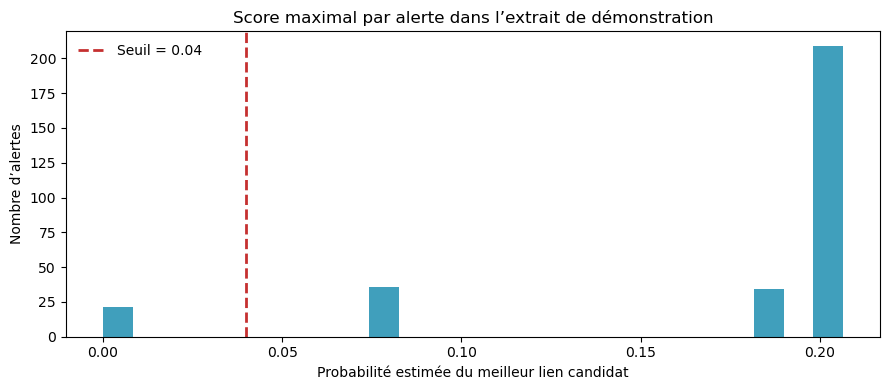

In [7]:
scores=[r['correlation_probability'] for r in responses]
fig,ax=plt.subplots(figsize=(9,4))
ax.hist(scores,bins=25,color='#168aad',alpha=.82)
ax.axvline(threshold,color='#c53030',linestyle='--',linewidth=2,label=f'Seuil = {threshold:.2f}')
ax.set_title('Score maximal par alerte dans l’extrait de démonstration')
ax.set_xlabel('Probabilité estimée du meilleur lien candidat')
ax.set_ylabel('Nombre d’alertes')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Schéma des premiers liens proposés

Chaque trait relie l’alerte reçue à une alerte précédente retenue par le scoreur. La force du lien correspond à sa probabilité estimée. Ce dessin illustre la sortie du prototype ; il ne constitue pas une validation indépendante de ces liens.

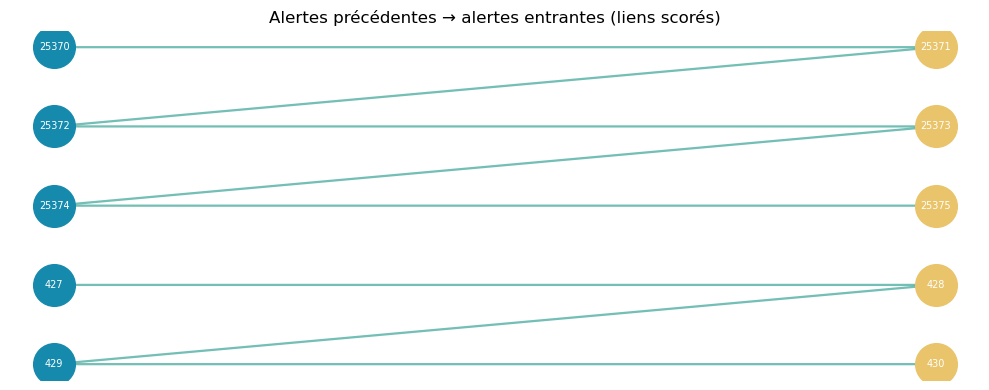

In [8]:
edges=[]
for response in linked:
    for relation in response['related_to']:
        edges.append((relation['alert_id'],response['alert_id'],relation['correlation_probability']))
    if len(edges)>=8: break

fig,ax=plt.subplots(figsize=(10,4))
if edges:
    nodes=[]
    for left,right,_ in edges:
        if left not in nodes:nodes.append(left)
        if right not in nodes:nodes.append(right)
    positions={node:(0 if i%2==0 else 1, -(i//2)) for i,node in enumerate(nodes)}
    for left,right,prob in edges:
        x1,y1=positions[left];x2,y2=positions[right]
        ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops=dict(arrowstyle='->',alpha=.45+min(prob,.5),color='#2a9d8f',lw=1+3*prob))
    for node,(x,y) in positions.items():
        ax.scatter(x,y,s=900,color='#168aad' if x==0 else '#e9c46a',zorder=3)
        ax.text(x,y,node.split(':')[-1][-10:],ha='center',va='center',fontsize=7,color='white',zorder=4)
    ax.set_title('Alertes précédentes → alertes entrantes (liens scorés)')
else:
    ax.text(.5,.5,'Aucun lien ne dépasse le seuil dans cet extrait.',ha='center',va='center',transform=ax.transAxes)
    ax.set_title('Aucun lien proposé pour cet extrait')
ax.axis('off');fig.tight_layout();plt.show()

## Limites du service

- L’historique est en mémoire et disparaît au redémarrage.
- Les clés et leurs noms doivent être identiques à ceux du prétraitement.
- Le score sert au tri et à l’examen humain, pas à confirmer seul un incident.
- Les labels disponibles décrivent des fenêtres d’attaque ; ils ne valident pas les liens retournés.

**Résumé :** le service prend une alerte, la compare à une courte mémoire, calcule des probabilités de paire et retourne les rapprochements dépassant le seuil.